In [39]:
import pandas as pd
from gensim.models import Word2Vec
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings("ignore")

# Read data
df = pd.read_csv('country-list.csv')
print(f"Number of country-capital pairs: {len(df)}\n")
print(f"{df.describe()}\n")

# Tokenize city and country names
tokenized_data = []
for row in df.itertuples():
    tokenized_data.append(row.capital.split() + row.country.split())
print(f"{tokenized_data}\n")

# Train Word2Vec model
model = Word2Vec(sentences=tokenized_data, vector_size=100, window=5, min_count=1, workers=4)

# Extract features
X = []
for city in df['capital']:
    if city in model.wv:
        X.append(model.wv[city])
    else:
        # Handle missing city names by using a zero vector
        X.append([0] * 100)  # Assuming vector_size is 100

y = df['country']

print(X)
print(y)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train RandomForestClassifier
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# Evaluate classifier
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)


Number of country-capital pairs: 248

        country     capital            type
count       248         248             248
unique      247         244               1
top     Bolivia  Georgetown  countryCapital
freq          2           2             248

[['Sukhumi', 'Abkhazia'], ['Kabul', 'Afghanistan'], ['Episkopi', 'Cantonment', 'Akrotiri', 'and', 'Dhekelia'], ['Tirana', 'Albania'], ['Algiers', 'Algeria'], ['Pago', 'Pago', 'American', 'Samoa'], ['Andorra', 'la', 'Vella', 'Andorra'], ['Luanda', 'Angola'], ['The', 'Valley', 'Anguilla'], ['St.', "John's", 'Antigua', 'and', 'Barbuda'], ['Buenos', 'Aires', 'Argentina'], ['Yerevan', 'Armenia'], ['Oranjestad', 'Aruba'], ['Georgetown', 'Ascension', 'Island'], ['Canberra', 'Australia'], ['Vienna', 'Austria'], ['Baku', 'Azerbaijan'], ['Nassau', 'Bahamas'], ['Manama', 'Bahrain'], ['Dhaka', 'Bangladesh'], ['Bridgetown', 'Barbados'], ['Minsk', 'Belarus'], ['Brussels', 'Belgium'], ['Belmopan', 'Belize'], ['Porto-Novo', 'Benin'], ['Hamilton', 

The csv file used came from https://github.com/icyrockcom/country-capitals/blob/master/data/country-list.csv. Each row in the csv contains a unique capital and country. This fact explains the accuracy score of 0 by the Random Classifier model, since each row in the test data had not been previously seen by the model during the training phase.

In [58]:
for cap in df['capital']:
    try:
        print(cap, clf.predict(model.wv[cap].reshape(1, -1)))
    except KeyError:
        pass

Sukhumi ['Abkhazia']
Kabul ['Afghanistan']
Tirana ['Albania']
Algiers ['Algeria']
Luanda ['Angola']
Yerevan ['Armenia']
Oranjestad ['Aruba']
Georgetown ['Guyana']
Canberra ['Australia']
Vienna ['Norway']
Baku ['Australia']
Nassau ['Bahamas']
Manama ['Samoa']
Dhaka ['Mauritania']
Bridgetown ['Barbados']
Minsk ['Belarus']
Brussels ['Belgium']
Belmopan ['Belize']
Porto-Novo ['Colombia']
Hamilton ['Guinea']
Thimphu ['Bhutan']
Sucre ['Bolivia']
Sarajevo ['Bosnia and Herzegovina']
Gaborone ['Czech Republic']
Brasília ['Brazil']
Sofia ['Bulgaria']
Ouagadougou ['Burkina Faso']
Bujumbura ['Burundi']
Yaoundé ['Venezuela']
Ottawa ['Canada']
Praia ['Cape Verde']
Bangui ['Central African Republic']
N'Djamena ['Chad']
Santiago ['Chile']
Beijing ['Saint Barthélemy']
Bogotá ['Colombia']
Moroni ['Comoros']
Avarua ['Cook Islands']
Zagreb ['Croatia']
Havana ['Cuba']
Willemstad ['Curaçao']
Nicosia ['Iraq']
Prague ['Czech Republic']
Yamoussoukro ["Côte d'Ivoire"]
Kinshasa ['Democratic Republic of the Congo

The model seems incapable of predicting a country if the capital has more than one word in its name (it raises a KeyError). Otherwise, the model appears to be fairly accurate. I don't know why some predictions are incorrect.

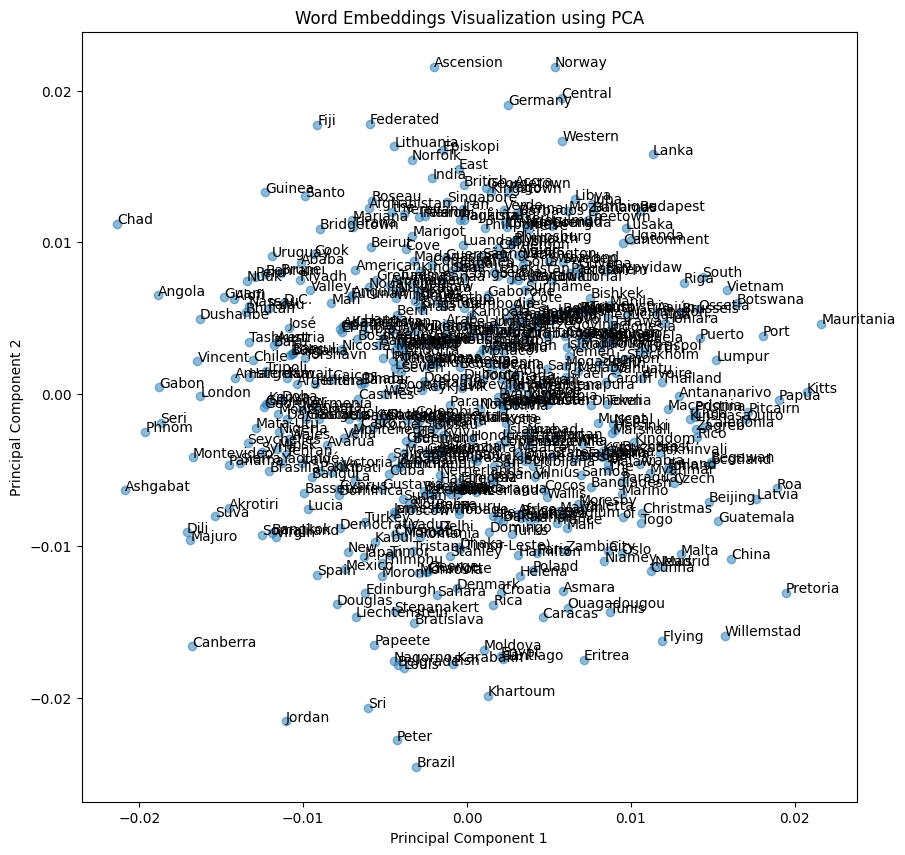

In [37]:
# Get the vocabulary and corresponding word embeddings
vocab = list(model.wv.key_to_index.keys())
word_embeddings = [model.wv[word] for word in vocab]

# Apply PCA to reduce dimensionality
pca = PCA(n_components=2)
pca_result = pca.fit_transform(word_embeddings)

# Plot the reduced-dimensional embeddings
plt.figure(figsize=(10, 10))
plt.scatter(pca_result[:, 0], pca_result[:, 1], alpha=0.5)
for i, word in enumerate(vocab):
    plt.annotate(word, xy=(pca_result[i, 0], pca_result[i, 1]))
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Word Embeddings Visualization using PCA')
plt.show()

In [63]:

def compute_cosine_sim(word1, word2):
    # Get the word embeddings for the words
    embedding1 = model.wv[word1].reshape(1, -1)  # Reshape to make it a row vector
    embedding2 = model.wv[word2].reshape(1, -1)  # Reshape to make it a row vector

    # Compute cosine similarity between the word embeddings
    similarity = cosine_similarity(embedding1, embedding2)[0, 0]

    # Print the cosine similarity
    print(f"Cosine similarity between '{word1}' and '{word2}': {similarity}")

compute_cosine_sim("States", "Paris")
compute_cosine_sim("France", "Paris")
compute_cosine_sim("London", "Kingdom")
compute_cosine_sim("Tokyo", "Japan")
compute_cosine_sim("Ottawa", "Canada")
compute_cosine_sim("Moscow", "Russia")
compute_cosine_sim("Beijing", "China")
compute_cosine_sim("Manila", "Brazil")


Cosine similarity between 'States' and 'Paris': -0.05477641150355339
Cosine similarity between 'France' and 'Paris': 0.002951384522020817
Cosine similarity between 'London' and 'Kingdom': -0.04287462309002876
Cosine similarity between 'Tokyo' and 'Japan': 0.11407359689474106
Cosine similarity between 'Ottawa' and 'Canada': -0.07168670743703842
Cosine similarity between 'Moscow' and 'Russia': 0.06080600991845131
Cosine similarity between 'Beijing' and 'China': 0.095693439245224
Cosine similarity between 'Manila' and 'Brazil': -0.15778280794620514


Generally, the cosine similarity of a capital to a country appear to be around 0, indicating moderate similarity. This appears to be true even for incorrect capital-country pairs.